# M14.5 — Evaluación de la cabeza con covarianza completa (M14.5a / M14.5b)

**Pre-registro:** `docs/experiments/M14_5_fullcov_head.md` (11-11-2026), aplicado literalmente.

**Procedencia.** Modelo `MODEL_TAG` (último epoch, `_final.pt`), inferencia fp16 sobre G3T (`preds_{cal,val}_G3T`, configs `configs/prediction/predict_m14_5{a,b}_*_on_G3T_{cal,val}.json`). Las predicciones de val de la decisión son las de la inferencia; el npz del entrenador solo se usa en el gate de reproducción. P de M14.4 se reconstruye a partir de las predicciones de M14.1 (cal y val), con el mismo código que M14.4, y se exige reproducir sus radios y su cobertura. Todo es CPU sobre predicciones guardadas: no se cargan modelos ni X (de X de val solo se lee la cabecera para el dtype). Test no se usa.

**Criterios (val G3T; radios en cal G3T).**
1. **C1, salvaguarda de μ:** ΔRMSE% por etiqueta frente a la referencia (M14.1 para a; M14.2 para b), bootstrap emparejado B = 2000, `default_rng(145001)`. PASA si IC sup ≤ +4 %; FALLA si el punto > +4 %; INDETERMINADO en otro caso.
2. **C2, calibración conjunta (con veredicto, no decide):** s = rᵀ Σ⁻¹ r frente a χ²₃; mean(s)/3 ∈ [0,9; 1,1] y fracción s ≤ 6,251 ∈ [0,88; 0,92] en 7 celdas: global, D1–D3 / D4–D7 / D8–D10 de τ30 predicha (cortes en cal) y terciles de σ_chirp (cortes en cal).
3. **C3, primario:** elipsoide conformal 3D con la Σ aprendida (radio = k-ésimo s de cal, k = ⌈(n + 1)·0,9⌉) frente a P de M14.4 en las mismas filas de val. Validez: cobertura conjunta global en la banda binomial al 95 % de 0,90. Δ = 100·(exp(mean log V_Σ − mean log V_P) − 1), volumen físico (Σ_phys = S Σ S, S = diag(y_std)), IC por bootstrap emparejado (B = 2000, `default_rng(145002)`).
   - **Adopción:** Σ aprendida si C1 no FALLA, es válida y el IC sup de Δ < 0. Si no, P (D R_g D) con la D del nuevo modelo.

**Descriptivos (no deciden):** cobertura conjunta por grupos de τ30 predicha y terciles de SNR nominal; 2D (𝓜, M_tot); correlación implícita de Σ(x) por decil frente a la empírica de z y a las R_g de M14.4; Mondrian v2 de M14.3 con σ = √diag Σ.

**No se puede concluir:** una semilla; sin datos reales; b frente a a mezcla dos factores (solo descriptivo).

## 1. Parámetros y CONFIG

In [1]:
# ---- Variant: edit only MODEL_TAG ----
MODEL_TAG = "M14_5a_4a_G3T_fullcov_s123"          # or "M14_5b_4a_G3T_tbank_fullcov_s123"

VARIANTS = {
    "M14_5a_4a_G3T_fullcov_s123": dict(
        train_cfg="configs/experiments/m14/train_m14_5a_4aG3T_fullcov_s123.json", template_bank=False,
        ref_tag="M14_1_4a_G3T_hetero_s123",       # C1 reference (one factor: diagonal sigma -> full Sigma)
        ref_val_rel="M13_3/M14_1_4a_G3T_hetero_s123/preds_val_G3T/val_predictions_embeddings.npz"),
    "M14_5b_4a_G3T_tbank_fullcov_s123": dict(
        train_cfg="configs/experiments/m14/train_m14_5b_4aG3T_tbank_fullcov_s123.json", template_bank=True,
        ref_tag="M14_2_4a_G3T_tbank_s123",        # C1 reference; homoscedastic: C1 uses only mu
        # No G3T inference config exists for M14.2: its trainer npz (read from the val fp16 memmap) is used,
        # the same file as the M14.2 evaluation.
        ref_val_rel="M13_3/M14_2_4a_G3T_tbank_s123/val_predictions_embeddings.npz"),
}
VARIANT = VARIANTS[MODEL_TAG]
REF_TAG = VARIANT["ref_tag"]
REF_VAL_REL = VARIANT["ref_val_rel"]
TRAIN_CFG_REL = VARIANT["train_cfg"]
EXPECTED_CHECKPOINT_NAME = f"{MODEL_TAG}_final.pt"
CHECKPOINT_REL = f"M13_3/{MODEL_TAG}_final.pt"    # relative to <data_root>/models/checkpoints/; never loaded,
                                                  # only recorded in the v1 bundle metadata (M13.7 cell 6)
G3T_MARK = "m13_13_g3t"
MEMMAP_NAMES = {"cal": "fp16_memmap_heldout", "val": "fp16_memmap"}   # only row_ids_<split>.npy (and X_val header)

# Inputs (relative to <data_root>/results/). Test: only in section 9d (amendment 2, post hoc).
PRED_REL = {s: f"M13_3/{MODEL_TAG}/preds_{s}_G3T/{s}_predictions_embeddings.npz" for s in ("cal", "val")}
TRAIN_VAL_REL = f"M13_3/{MODEL_TAG}/val_predictions_embeddings.npz"   # trainer npz: only for the reproduction gate
RUN_INFO_REL = f"M13_3/{MODEL_TAG}/run_info.json"
HISTORY_REL = f"M13_3/{MODEL_TAG}/history.npz"                         # per-epoch record of the training log

# P of M14.4: M14.1 inference on G3T (same files as M14.4).
P_TAG = "M14_1_4a_G3T_hetero_s123"
P_TRAIN_CFG_REL = "configs/experiments/m14/train_m14_1_4aG3T_hetero_s123.json"
P_PRED_REL = {"cal": f"M13_3/{P_TAG}/preds_cal_G3T/cal_predictions_embeddings.npz",
              "val": f"M13_3/{P_TAG}/preds_val_G3T/val_predictions_embeddings.npz"}
M14_4_SUMMARY_NAME = "M14_4_summary_20261111T175754Z.json"
P_EXPECTED = {"radius_3D": (6.4054, 4), "radius_2D": (4.5383, 4), "coverage_val_3D": (0.9007, 4)}   # (value, decimals)

G3_CFG_REL = "configs/experiments/m13/train_m13_4a_G3aug_s123.json"   # G3 HDF5: y and SNR, as in M14.1/M14.4
SNR_KEY = "target_network_snr"

# Gates.
N_EXPECTED = {"cal": 30_000, "val": 40_000}
N_EPOCHS = 80
Y_RTOL, Y_ATOL = 1e-5, 1e-6
SYM_ATOL = 1e-6          # max |Sigma - Sigma^T| (standardized)
SIGMA_ATOL = 1e-6        # sigma_<split> = sqrt(diag cov_<split>)
REPRO_TOL = 1e-5         # inference fp16 vs trainer npz: max |dmu|, |dcov| (standardized)
MSE_LOG_ATOL = 5e-4      # standardized MSE of mu (inference) vs last epoch of history.npz
REPRO_ATOL = 1e-12

# Executed M14.3 run: SNR tercile cuts; M13.7 and M11 references used by the reused M13.7 cell 6.
M14_3_SUMMARY_NAME = "M14_3_summary_20261111T153122Z.json"
M13_7_RUN = "run_20261102T164134Z"
PRIMARY_POLICY = "conservative"

# Pre-registered design.
LEVEL = 0.90
N_TAU_DECILES = 10
TAU_GROUPS = {"D1-D3": (0, 1, 2), "D4-D7": (3, 4, 5, 6), "D8-D10": (7, 8, 9)}   # decile indices 0..9
DIMS = {"3D": (0, 1, 2), "2D": (0, 1)}                                        # 2D = (chirp, total)
VALID_BAND_LEVEL = 0.95
CI_LEVEL = 0.95
BOOT_BLOCK = 50                                    # replicates per vectorised block (memory only)
N_BOOT_C1, SEED_C1, C1_MARGIN_PCT = 2000, 145001, 4.0
CHI2_3_Q90 = 6.251                                 # doc value (0.90 quantile of chi2_3)
C2_MEAN_BAND, C2_FRAC_BAND = (0.9, 1.1), (0.88, 0.92)
N_BOOT_C3, SEED_C3 = 2000, 145002

CONFIG = dict(
    methods=dict(S=dict(name="Σ aprendida (M14.5)", color="#2a6fb0", ls="-"),
                 P=dict(name="P de M14.4 (M14.1, R por decil)", color="0.35", ls="--")),
    v2=dict(name="rectángulo v2 (M14.3, σ de Σ)", color="#c4512b"),
    labels={"chirp_mass": "chirp mass", "total_mass": "total mass", "chi_eff": "χ_eff"},
    units={"chirp_mass": "M☉", "total_mass": "M☉", "chi_eff": "adim."},
    implied_color="#2a6fb0", empirical_color="#c4512b", rg_color="0.35", truth_color="k",
    fig_names=dict(a=f"{MODEL_TAG}_val_implied_vs_empirical_corr_by_tau_pred_decile",
                   b=f"{MODEL_TAG}_val_ellipses_2d_examples"),
)

## 2. Imports, rutas y código reutilizado

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, chi2
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.conformal.selected_calibrators import fit_selected_calibrators   # used by the reused M13.7 cell 6
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.conformal.binning import BinGrouper                     # used by the reused fit_v2
from src.conformal.calibration import ConformalIntervalCalibrator  # used by the reused fit_v2
from scripts.m13.m13_1_diagnostics import tau_newtonian   # same tau30 as M14.1, M14.3 and M14.4

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
POLICIES = ["conservative", "efficient"]   # read by the reused M13.7 cell 6

train_cfg = read_json(PROJECT_ROOT / TRAIN_CFG_REL)
p_train_cfg = read_json(PROJECT_ROOT / P_TRAIN_CFG_REL)
require(train_cfg["outputs"]["checkpoint_tag"] == MODEL_TAG, "train config checkpoint_tag != MODEL_TAG")
require(train_cfg["model"].get("heteroscedastic") is True and train_cfg["model"].get("covariance") == "full",
        "train config is not a full-covariance heteroscedastic model")
require(bool(train_cfg["model"].get("template_bank")) == VARIANT["template_bank"], "template bank flag of the variant")
require(train_cfg["dataset"] == p_train_cfg["dataset"], "dataset block (split, scaler) = M14.1")
require(train_cfg["input_normalization"] == p_train_cfg["input_normalization"], "input normalization = M14.1")
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID_G3T = train_cfg["dataset"]["dataset_id"]
require(DATASET_ID_G3T == f"M13_G3_band1024_w16_500k/{G3T_MARK}", "Unexpected dataset")
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
g3_ds = read_json(PROJECT_ROOT / G3_CFG_REL)["dataset"]
DATASET_ID_G3 = g3_ds["dataset_id"]
require(G3T_MARK not in DATASET_ID_G3 and DATASET_ID_G3T == f"{DATASET_ID_G3}/{G3T_MARK}", "G3 / G3T dataset ids")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3, file_name=g3_ds["dataset_file"])
G3T_DIR = DATA_ROOT / "processed" / DATASET_ID_G3T
MEMMAP_DIRS = {s: G3T_DIR / name for s, name in MEMMAP_NAMES.items()}

RESULTS = DATA_ROOT / "results"
M13_DIR = RESULTS / "M13_3"
PRED_PATHS = {s: RESULTS / rel for s, rel in PRED_REL.items()}
TRAIN_VAL_NPZ = RESULTS / TRAIN_VAL_REL
RUN_INFO = RESULTS / RUN_INFO_REL
HISTORY = RESULTS / HISTORY_REL
REF_VAL_NPZ = RESULTS / REF_VAL_REL
P_PATHS = {s: RESULTS / rel for s, rel in P_PRED_REL.items()}
CHECKPOINT = DATA_ROOT / "models/checkpoints" / CHECKPOINT_REL
M14_4_SUMMARY = M13_DIR / "M14_4" / M14_4_SUMMARY_NAME
M14_3_SUMMARY = M13_DIR / "M14_3" / M14_3_SUMMARY_NAME
M13_7_DIR = M13_DIR / "M13_4b_G3aug_s123" / "M13_7_pipeline_provisional" / M13_7_RUN
M13_7_SUMMARY = M13_7_DIR / f"M13_7_summary_{M13_7_RUN.removeprefix('run_')}.json"
M11_RESULTS = RESULTS / "M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"
M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
M14_3_NOTEBOOK = PROJECT_ROOT / "notebooks/m14/M14_3_mondrian_v2.ipynb"
M14_4_NOTEBOOK = PROJECT_ROOT / "notebooks/m14/M14_4_residual_correlation.ipynb"

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT_ROOT = M13_DIR / "M14_5" / MODEL_TAG
FIG_DIR = OUT_ROOT / "figures"
RUN_DIR = OUT_ROOT / f"run_{RUN_STAMP}"      # v1 bundle written by the reused M13.7 cell 6 (cal-only refit)
require(not RUN_DIR.exists(), "Output of this stamp already exists")

inputs_to_check = [("pred cal", PRED_PATHS["cal"]), ("pred val", PRED_PATHS["val"]),
    ("trainer val npz", TRAIN_VAL_NPZ), ("trainer run_info", RUN_INFO), ("trainer history", HISTORY),
    (f"C1 reference val ({REF_TAG})", REF_VAL_NPZ), ("P: M14.1 pred cal", P_PATHS["cal"]), ("P: M14.1 pred val", P_PATHS["val"]),
    ("checkpoint (not loaded)", CHECKPOINT),
    ("row_ids cal", MEMMAP_DIRS["cal"] / "row_ids_cal.npy"), ("row_ids val", MEMMAP_DIRS["val"] / "row_ids_val.npy"),
    ("X val (header only)", MEMMAP_DIRS["val"] / "X_val.npy"),
    ("G3 HDF5 (y, SNR)", G3_H5), ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH),
    ("M14.4 summary", M14_4_SUMMARY), ("M14.3 summary", M14_3_SUMMARY), ("M13.7 summary", M13_7_SUMMARY),
    ("M11 selection (val)", M11_SELECTION), ("M11 bundle manifest", M11_BUNDLE_MANIFEST),
    ("M13.7 notebook", M13_7_NOTEBOOK), ("M14.3 notebook", M14_3_NOTEBOOK), ("M14.4 notebook", M14_4_NOTEBOOK)]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")
print("Model:", MODEL_TAG, "| C1 reference:", REF_TAG, "| run stamp:", RUN_STAMP)

# Reuse of closed notebooks without copying them (same mechanism as M14.3 and M14.4, cell 4).
NOTEBOOK_CELLS = {"M13_7": read_json(M13_7_NOTEBOOK)["cells"], "M14_3": read_json(M14_3_NOTEBOOK)["cells"],
                  "M14_4": read_json(M14_4_NOTEBOOK)["cells"]}
reused_sources = {}

def reuse_cell(source, cell_index, names=None):
    """Run a code cell of a closed notebook here, or define only its functions `names`."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    if names is not None:
        tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
        require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

reuse_cell("M13_7", 11, ["read_hdf5_dataset_preserve_order"])
reuse_cell("M14_3", 12, ["fit_v2"])
reuse_cell("M14_3", 14, ["apply_v2", "per_row"])
reuse_cell("M14_3", 34, ["to_json", "records", "input_entry"])
reuse_cell("M14_4", 14, ["binom_band"])     # defaults bound here: p = LEVEL, level = VALID_BAND_LEVEL
reuse_cell("M14_4", 18, ["v1_on_split"])    # v1 on one split with the calls of M13.7 cell 8 (no CSV)
print(json.dumps(reused_sources, indent=2))

,role,path,exists
0,pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
1,pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_val_G3T/val_predictions_embeddings.npz,True
2,trainer val npz,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/val_predictions_embeddings.npz,True
3,trainer run_info,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/run_info.json,True
4,trainer history,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/history.npz,True
5,C1 reference val (M14_1_4a_G3T_hetero_s123),/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_val_G3T/val_predictions_embeddings.npz,True
6,P: M14.1 pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
7,P: M14.1 pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_val_G3T/val_predictions_embeddings.npz,True
8,checkpoint (not loaded),/data/vserrano/cbc_pe_data/models/checkpoints/M13_3/M14_5a_4a_G3T_fullcov_s123_final.pt,True
9,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True


Model: M14_5a_4a_G3T_fullcov_s123 | C1 reference: M14_1_4a_G3T_hetero_s123 | run stamp: 20261112T142455Z
{
  "M13_7/cell_11": {
    "names": [
      "read_hdf5_dataset_preserve_order"
    ],
    "sha256": "f099a982debdc92ba1beff856b10043efd228a7fd7f2ee23d2499566f4e25a0c"
  },
  "M14_3/cell_12": {
    "names": [
      "fit_v2"
    ],
    "sha256": "fd500ea8577bd520c3f11b32ef9c4491e8c10edbc72bbc0c14cf42c651719b7d"
  },
  "M14_3/cell_14": {
    "names": [
      "apply_v2",
      "per_row"
    ],
    "sha256": "8bba8df74aa45892444429a72a19a109e94f849dc4059f6f0f1a5bb49d562b68"
  },
  "M14_3/cell_34": {
    "names": [
      "to_json",
      "records",
      "input_entry"
    ],
    "sha256": "d21af75086d1b12331dc24d1a10896677c2ea7e8909e037917f1bf465087d512"
  },
  "M14_4/cell_14": {
    "names": [
      "binom_band"
    ],
    "sha256": "47656f33c658865b1d646ac94fcd7c782f9e8d7580db3dde229a534777446400"
  },
  "M14_4/cell_18": {
    "names": [
      "v1_on_split"
    ],
    "sha256": "a687ac3

## 3. Gates (si falla alguno, el notebook se para)

- **Procedencia** de los npz (modelo cal/val, npz del entrenador, referencia de C1 y M14.1 para P): split único, orden de etiquetas, checkpoint, tipo de cabeza, memmap, split, escalador train-only y normalización de entrada.
- **idx = split = row_ids**, sin solape cal/val; mismas filas y mismo orden en modelo, M14.1 y referencia (emparejamiento).
- **y = HDF5 de G3** (unidades físicas).
- **cov_<split>**: presente, finita, simétrica (|Σ − Σᵀ| ≤ 1e-6) y definida positiva en todas las filas; sigma = √diag Σ con atol 1e-6.

In [3]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}

def load_pred(path, s, ckpt_name, kind):
    """kind: 'full' (M14.5: sigma, cov, emb), 'diag' (M14.1: sigma), 'mu' (C1 reference: mu only)."""
    tag = f"{Path(ckpt_name).stem}/{s} ({path.parent.name})"
    with np.load(path, allow_pickle=True) as z:
        check(z["available_splits"].tolist() == [s], f"{tag}: npz holds only split {s}")
        check(z["label_names"].tolist() == LABELS, f"{tag}: label order {LABELS}")
        check(np.array_equal(z["y_mean"], stats_mean) and np.array_equal(z["y_std"], stats_std),
              f"{tag}: y_mean/y_std = train-only label stats")
        prov = {k: str(z[k].item()) for k in ("checkpoint_file", "split_path", "label_stats_path", "memmap_dir")}
        mk = z["model_config"].item()["model_kwargs"]
        prov.update(model_class=z["model_config"].item()["class_name"],
                    heteroscedastic=bool(mk.get("heteroscedastic", False)), covariance=mk.get("covariance", "diag"),
                    template_bank=bool(mk.get("template_bank")), input_normalization=z["input_normalization"].item())
        d = dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                 y=np.asarray(z[f"y_{s}"], dtype=float))
        if kind in ("full", "diag"):
            check(f"sigma_{s}" in z.files, f"{tag}: sigma_{s} present")
            d["sigma"] = np.asarray(z[f"sigma_{s}"], dtype=float)
        if kind == "full":
            check(f"cov_{s}" in z.files, f"{tag}: cov_{s} present (full-covariance model)")
            d["cov"] = np.asarray(z[f"cov_{s}"], dtype=float)
            d["emb"] = np.asarray(z[f"emb_{s}"], dtype=float)    # emb: only for the v1 difficulty taxonomy
    check(Path(prov["checkpoint_file"]).name == ckpt_name, f"{tag}: checkpoint_file is {ckpt_name}")
    if kind == "full":
        check(prov["heteroscedastic"] and prov["covariance"] == "full", f"{tag}: heteroscedastic, covariance = full")
        check(prov["template_bank"] == VARIANT["template_bank"], f"{tag}: template bank = {VARIANT['template_bank']}")
    elif kind == "diag":
        check(prov["heteroscedastic"] and prov["covariance"] == "diag", f"{tag}: heteroscedastic, covariance = diag")
    mm = Path(prov["memmap_dir"]).parts
    check(mm[-3:-1] == (DATASET_ID_G3, G3T_MARK) and mm[-1] == MEMMAP_DIRS[s].name,
          f"{tag}: memmap_dir is {DATASET_ID_G3}/{G3T_MARK}/{MEMMAP_DIRS[s].name}")
    check(Path(prov["split_path"]).name == SPLIT_PATH.name, f"{tag}: split file")
    check(Path(prov["label_stats_path"]).name == LABEL_STATS_PATH.name, f"{tag}: label stats file")
    check(prov["input_normalization"] == train_cfg["input_normalization"], f"{tag}: input normalization contract")
    return d, prov

SPLITS, NPZ_PROVENANCE = {}, {}
for s, path in PRED_PATHS.items():
    SPLITS[s], NPZ_PROVENANCE[f"model/{s}"] = load_pred(path, s, EXPECTED_CHECKPOINT_NAME, "full")
TRAIN_VAL, NPZ_PROVENANCE["trainer/val"] = load_pred(TRAIN_VAL_NPZ, "val", EXPECTED_CHECKPOINT_NAME, "full")
REF_VAL, NPZ_PROVENANCE["c1_reference/val"] = load_pred(REF_VAL_NPZ, "val", f"{REF_TAG}_final.pt", "mu")
P_SPLITS = {}
for s, path in P_PATHS.items():
    P_SPLITS[s], NPZ_PROVENANCE[f"P_m14_1/{s}"] = load_pred(path, s, f"{P_TAG}_final.pt", "diag")
EMB_DIM = SPLITS["cal"]["emb"].shape[1]

for s, d in SPLITS.items():
    n = len(split_indices[s])
    check(n == N_EXPECTED[s], f"{s}: n = {N_EXPECTED[s]}")
    check(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"{s}: {n} unique idx")
    for name, shape in (("pred", (n, 3)), ("sigma", (n, 3)), ("y", (n, 3)), ("emb", (n, EMB_DIM)), ("cov", (n, 3, 3))):
        check(d[name].shape == shape and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")
    check(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    row_ids = np.load(MEMMAP_DIRS[s] / f"row_ids_{s}.npy").astype(np.int64)
    check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {MEMMAP_DIRS[s].name}")
    # Pairing: identical rows, in identical order, in M14.1 (P) and, for val, in the trainer npz and the C1 reference.
    others = [("P (M14.1)", P_SPLITS[s])] + ([("trainer", TRAIN_VAL), ("C1 reference", REF_VAL)] if s == "val" else [])
    for name, o in others:
        check(np.array_equal(o["idx"], d["idx"]), f"{s}: {name} idx = model idx (same order)")
        check(np.allclose(o["y"], d["y"], rtol=0, atol=Y_ATOL), f"{s}: {name} y = model y")
        check(np.isfinite(o["pred"]).all() and o["pred"].shape == (n, 3), f"{s}: {name} pred shape and finite")
    check(P_SPLITS[s]["sigma"].shape == (n, 3) and np.all(P_SPLITS[s]["sigma"] > 0), f"{s}: P sigma > 0")
check(np.intersect1d(SPLITS["cal"]["idx"], SPLITS["val"]["idx"]).size == 0, "no overlap cal/val")

with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID_G3, "G3 HDF5 experiment_id")
    check(str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 label order")
    y_h5 = {s: read_hdf5_dataset_preserve_order(h, "y", SPLITS[s]["idx"]).astype(float) for s in SPLITS}
for s in SPLITS:
    y_phys = SPLITS[s]["y"] * y_std + y_mean
    print(f"{s}: max |y_npz - y_G3h5| (physical) =", np.abs(y_phys - y_h5[s]).max(0))
    check(np.isclose(y_phys, y_h5[s], rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: y = y of the G3 HDF5")

# Learned covariance (standardized units).
cov_rows = []
for s, d in {**SPLITS, "val (trainer)": TRAIN_VAL}.items():
    C = d["cov"]
    asym = float(np.abs(C - C.transpose(0, 2, 1)).max())
    eig_min = np.linalg.eigvalsh(C).min(1)
    dsig = float(np.abs(d["sigma"] - np.sqrt(np.diagonal(C, axis1=1, axis2=2))).max())
    cov_rows.append(dict(split=s, max_asym=asym, min_eig=float(eig_min.min()), n_nonpd=int((eig_min <= 0).sum()),
                         max_abs_dsigma=dsig))
    check(asym <= SYM_ATOL, f"{s}: cov symmetric (max |S - S^T| <= {SYM_ATOL:g})")
    check(np.all(eig_min > 0), f"{s}: cov positive definite in every row")
    check(dsig <= SIGMA_ATOL, f"{s}: sigma = sqrt(diag cov) (atol {SIGMA_ATOL:g})")
COV_GATE = pd.DataFrame(cov_rows)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(COV_GATE)
n_cal, n_val = len(SPLITS["cal"]["idx"]), len(SPLITS["val"]["idx"])
IDX_VAL = SPLITS["val"]["idx"]
print("GATES superados:", len(CHECKS), "comprobaciones")

cal: max |y_npz - y_G3h5| (physical) = [2.26102156e-06 7.93715662e-06 6.16398950e-08]
val: max |y_npz - y_G3h5| (physical) = [2.34669051e-06 7.88831312e-06 6.16673788e-08]


,split,max_asym,min_eig,n_nonpd,max_abs_dsigma
0,cal,0,6.04e-05,0,5.37e-08
1,val,0,5.69e-05,0,5.44e-08
2,val (trainer),0,5.69e-05,0,5.9e-08


GATES superados: 110 comprobaciones


### Gate de reproducción de val y MSE de la última época

- El entrenador leyó X de val del memmap fp16 de G3T (`run_info.data.memmap_dir`; de X solo se lee la cabecera). La inferencia fp16 (`preds_val_G3T`) frente al npz del entrenador: máx. |Δμ| y máx. |ΔΣ| ≤ 1e-5 (estandarizado, por elemento).
- MSE estandarizado de μ (inferencia, val) frente a `val_mse` de la última época de `history.npz` (el mismo valor que imprime el log), tolerancia absoluta 5e-4 por etiqueta.
- Las predicciones de val de la decisión son las de la inferencia.

In [4]:
run_info = read_json(RUN_INFO)
proc = run_info["procedure"]
check(proc.get("covariance") == "full" and str(proc.get("loss", "")).startswith("beta_nll_full"),
      "run_info: covariance = full, loss = beta_nll_full")
check(("template_bank" in proc) == VARIANT["template_bank"], "run_info: template bank as the variant")
TRAINER_VAL_DIR = Path(run_info["data"]["memmap_dir"])
check(TRAINER_VAL_DIR.resolve() == MEMMAP_DIRS["val"].resolve(), "trainer read val from the G3T fp16_memmap (run_info)")
x_val = np.load(TRAINER_VAL_DIR / "X_val.npy", mmap_mode="r")   # header only: dtype and shape, no data read
X_DTYPE, X_SHAPE = np.dtype(x_val.dtype), tuple(x_val.shape)
del x_val
print("Trainer val X dtype:", X_DTYPE, "| shape:", X_SHAPE)
check(X_DTYPE == np.float16, "trainer val X is float16 (same input as the fp16 inference)")

V = SPLITS["val"]
dmu = np.abs(V["pred"] - TRAIN_VAL["pred"])
dcov = np.abs(V["cov"] - TRAIN_VAL["cov"]).reshape(n_val, -1)
REPRO_TABLE = pd.DataFrame({"max |dmu|": dmu.max(0),
                            "max |dSigma_jj|": np.abs(np.diagonal(V["cov"] - TRAIN_VAL["cov"], axis1=1, axis2=2)).max(0)},
                           index=LABELS)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(REPRO_TABLE)
print("max |dcov| (all elements):", dcov.max())
check(dmu.max() <= REPRO_TOL and dcov.max() <= REPRO_TOL, f"val reproduction: max |dmu|, |dcov| <= {REPRO_TOL:g}")

with np.load(HISTORY, allow_pickle=True) as hz:
    check(hz["label_names"].tolist() == LABELS, "history: label order")
    epochs = np.asarray(hz["epoch"])
    MSE_LOG = np.asarray(hz["val_mse"], dtype=float)[-1]
check(len(epochs) == N_EPOCHS and int(epochs[-1]) == N_EPOCHS - 1, f"history: {N_EPOCHS} epochs, last = {N_EPOCHS - 1}")
MSE_INF = np.mean((V["pred"] - V["y"]) ** 2, 0)
MSE_TABLE = pd.DataFrame(dict(mse_inference=MSE_INF, mse_last_epoch_log=MSE_LOG, abs_diff=np.abs(MSE_INF - MSE_LOG)),
                         index=LABELS)
display(MSE_TABLE)
check(np.all(np.abs(MSE_INF - MSE_LOG) <= MSE_LOG_ATOL), f"standardized MSE of mu = last epoch (atol {MSE_LOG_ATOL:g})")
GATE_VAL = dict(trainer_val_dir=str(TRAINER_VAL_DIR), x_dtype=str(X_DTYPE), x_shape=X_SHAPE, tol=REPRO_TOL,
                max_abs_dmu=float(dmu.max()), max_abs_dcov=float(dcov.max()), mse=records(MSE_TABLE.rename_axis("label")),
                passed=True)
print("Gate de val superado. La decisión usa las predicciones de val de la inferencia fp16 (preds_val_G3T).")

Trainer val X dtype: float16 | shape: (40000, 3, 16384)


,max |dmu|,max |dSigma_jj|
chirp_mass,0,3.58e-07
total_mass,0,5.96e-08
chi_eff,0,2.38e-07


max |dcov| (all elements): 3.5762786865234375e-07


,mse_inference,mse_last_epoch_log,abs_diff
chirp_mass,0.102501,0.102501,0.0
total_mass,0.064635,0.064635,0.0
chi_eff,0.148334,0.148334,0.0


Gate de val superado. La decisión usa las predicciones de val de la inferencia fp16 (preds_val_G3T).


## 4. C1 — salvaguarda de μ (val)

ΔRMSE% = 100·(RMSE_modelo / RMSE_ref − 1) por etiqueta, en las mismas 40 000 filas de val (ΔRMSE% no depende de la escala, así que da lo mismo en unidades físicas o estandarizadas). Bootstrap emparejado por filas, B = 2000, `default_rng(145001)`; un mismo remuestreo para las tres etiquetas; IC percentil al 95 %. PASA si IC sup ≤ +4 %; FALLA si el punto > +4 %; INDETERMINADO en otro caso. Para b la referencia es M14.2 (sin σ): solo se usa μ.

In [5]:
SQ_M = ((V["pred"] - V["y"]) * y_std) ** 2
SQ_R = ((REF_VAL["pred"] - REF_VAL["y"]) * y_std) ** 2
C1_POINT = 100 * (np.sqrt(SQ_M.mean(0) / SQ_R.mean(0)) - 1)
rng_c1 = np.random.default_rng(SEED_C1)
boot_c1 = np.empty((N_BOOT_C1, 3))
for start in range(0, N_BOOT_C1, BOOT_BLOCK):
    b = min(BOOT_BLOCK, N_BOOT_C1 - start)
    idx = rng_c1.integers(0, n_val, size=(b, n_val))
    boot_c1[start:start + b] = 100 * (np.sqrt(SQ_M[idx].mean(1) / SQ_R[idx].mean(1)) - 1)
a = (1 - CI_LEVEL) / 2
c1_lo, c1_hi = np.quantile(boot_c1, [a, 1 - a], axis=0)

def c1_verdict(point, hi):
    if hi <= C1_MARGIN_PCT:
        return "PASA"
    if point > C1_MARGIN_PCT:
        return "FALLA"
    return "INDETERMINADO"

C1 = pd.DataFrame(dict(label=LABELS, rmse_model=np.sqrt(SQ_M.mean(0)), rmse_ref=np.sqrt(SQ_R.mean(0)),
                       delta_rmse_pct=C1_POINT, ci_lo_pct=c1_lo, ci_hi_pct=c1_hi))
C1["verdict"] = [c1_verdict(p, h) for p, h in zip(C1.delta_rmse_pct, C1.ci_hi_pct)]
with pd.option_context("display.float_format", "{:.4g}".format):
    display(C1)
C1_FAILS = bool((C1.verdict == "FALLA").any())
print(f"C1 (referencia {REF_TAG}):", dict(zip(C1.label, C1.verdict)), "| alguna FALLA:", C1_FAILS)

,label,rmse_model,rmse_ref,delta_rmse_pct,ci_lo_pct,ci_hi_pct,verdict
0,chirp_mass,5.285,5.268,0.3352,-0.03561,0.7337,PASA
1,total_mass,8.823,8.799,0.2732,-0.1704,0.6982,PASA
2,chi_eff,0.1696,0.1678,1.081,0.6511,1.499,PASA


C1 (referencia M14_1_4a_G3T_hetero_s123): {'chirp_mass': 'PASA', 'total_mass': 'PASA', 'chi_eff': 'PASA'} | alguna FALLA: False


## 5. Grupos

- Deciles de τ30 predicha por el modelo (𝓜 de μ), cortes en cal; grupos D1–D3 / D4–D7 / D8–D10.
- Terciles de σ_chirp del modelo (√Σ₁₁), cortes en cal.
- Terciles de SNR nominal de G3 (`target_network_snr`), cortes en val, iguales a los de M14.3 (y M14.4).

In [6]:
TAU_PRED = {s: tau_newtonian(d["pred"][:, 0] * y_std[0] + y_mean[0]) for s, d in SPLITS.items()}
for s in SPLITS:
    check(np.isfinite(TAU_PRED[s]).all(), f"{s}: predicted tau30 finite")
TAU_EDGES_CAL = np.quantile(TAU_PRED["cal"], np.linspace(0, 1, N_TAU_DECILES + 1))
DEC = {s: np.clip(np.searchsorted(TAU_EDGES_CAL[1:-1], TAU_PRED[s], side="right"), 0, N_TAU_DECILES - 1) for s in SPLITS}
for s in SPLITS:
    check(np.bincount(DEC[s], minlength=N_TAU_DECILES).min() > 0, f"{s}: every predicted tau30 decile populated")
TAU_GROUP_MASKS = {s: {g: np.isin(DEC[s], ds) for g, ds in TAU_GROUPS.items()} for s in SPLITS}
print("Predicted tau30 decile edges (cal) [s]:", np.round(TAU_EDGES_CAL, 4))
display(pd.DataFrame({s: np.bincount(DEC[s], minlength=N_TAU_DECILES) for s in SPLITS},
                     index=[f"D{k + 1}" for k in range(N_TAU_DECILES)]).T)

SIG_CHIRP_CUTS_CAL = np.quantile(SPLITS["cal"]["sigma"][:, 0], [1 / 3, 2 / 3])
sig_ter = np.searchsorted(SIG_CHIRP_CUTS_CAL, V["sigma"][:, 0], side="right")
SIG_GROUPS_VAL = {f"σchirp-T{t + 1}": sig_ter == t for t in range(3)}

M14_3_SUM = read_json(M14_3_SUMMARY)
with h5py.File(G3_H5, "r") as h:
    require(SNR_KEY in h, f"G3 HDF5 lacks {SNR_KEY}")
    check(IDX_VAL.min() >= 0 and IDX_VAL.max() < h[SNR_KEY].shape[0], "SNR: every idx_val exists in the G3 HDF5")
    SNR_VAL = read_hdf5_dataset_preserve_order(h, SNR_KEY, IDX_VAL).astype(float)
check(np.isfinite(SNR_VAL).all() and np.all(SNR_VAL > 0), f"{SNR_KEY} finite and positive")
SNR_CUTS = np.quantile(SNR_VAL, [1 / 3, 2 / 3])
check(np.allclose(SNR_CUTS, M14_3_SUM["secondary_snr"]["cuts"], rtol=0, atol=REPRO_ATOL), "SNR tercile cuts = M14.3")
snr_ter = np.searchsorted(SNR_CUTS, SNR_VAL, side="right")      # 0, 1, 2 (as M14.1, M14.3 and M14.4)
SNR_GROUPS_VAL = {f"SNR-T{t + 1}": snr_ter == t for t in range(3)}
print("sigma_chirp tercile cuts (cal, standardized):", SIG_CHIRP_CUTS_CAL, "| SNR tercile cuts (val):", SNR_CUTS)

Predicted tau30 decile edges (cal) [s]: [0.0547 0.0828 0.1033 0.1236 0.1469 0.1791 0.2258 0.2982 0.4293 0.684
 5.246 ]


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
cal,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000
val,3912,3894,3921,3951,4115,3994,3904,4138,4133,4038


sigma_chirp tercile cuts (cal, standardized): [0.16106238 0.32546658] | SNR tercile cuts (val): [14.95404436 19.98007806]


## 6. C2 — calibración conjunta de Σ (val; con veredicto, no decide)

s = rᵀ Σ⁻¹ r, r = y − μ, en unidades estandarizadas (invariante a la escala: es la misma s que con Σ_phys = S Σ S y r físico; se comprueba en 1000 filas). Bajo calibración perfecta s ~ χ²₃: mean(s)/3 ∈ [0,9; 1,1] y fracción s ≤ 6,251 ∈ [0,88; 0,92], en las 7 celdas del doc. Veredicto: calibrada si las 7 celdas cumplen ambas bandas.

In [7]:
def mahalanobis(d, cols):
    cols = list(cols)
    r = (d["y"] - d["pred"])[:, cols]
    C = d["cov"][:, cols][:, :, cols]
    return np.einsum("ni,ni->n", r, np.linalg.solve(C, r[..., None])[..., 0])

S_SIG = {(s, dim): mahalanobis(SPLITS[s], cols) for s in SPLITS for dim, cols in DIMS.items()}

n_chk = 1000
d_cal = SPLITS["cal"]
r_phys = (d_cal["y"][:n_chk] - d_cal["pred"][:n_chk]) * y_std
sigma_phys = d_cal["cov"][:n_chk] * y_std[None, :, None] * y_std[None, None, :]     # S Sigma S
direct = np.einsum("ni,ni->n", r_phys, np.linalg.solve(sigma_phys, r_phys[..., None])[..., 0])
check(np.allclose(direct, S_SIG[("cal", "3D")][:n_chk], rtol=1e-8, atol=1e-10), "s identity: standardized = physical")
print("chi2_3 0.90 quantile (scipy):", chi2.ppf(LEVEL, 3), "| doc value used:", CHI2_3_Q90)

s_val = S_SIG[("val", "3D")]
c2_cells = [("global", np.ones(n_val, bool))] + list(TAU_GROUP_MASKS["val"].items()) + list(SIG_GROUPS_VAL.items())
c2_rows = []
for g, mask in c2_cells:
    m3, frac = float(s_val[mask].mean() / 3), float((s_val[mask] <= CHI2_3_Q90).mean())
    c2_rows.append(dict(cell=g, n=int(mask.sum()), mean_s_over_3=m3, frac_s_le_q90=frac,
                        mean_ok=C2_MEAN_BAND[0] <= m3 <= C2_MEAN_BAND[1], frac_ok=C2_FRAC_BAND[0] <= frac <= C2_FRAC_BAND[1]))
C2 = pd.DataFrame(c2_rows)
C2["cell_ok"] = C2.mean_ok & C2.frac_ok
with pd.option_context("display.float_format", "{:.4f}".format):
    display(C2)
C2_VERDICT = "calibrada" if C2.cell_ok.all() else "no calibrada"
print(f"C2 (no decide): {C2_VERDICT} ({int(C2.cell_ok.sum())}/{len(C2)} celdas en ambas bandas)")

chi2_3 0.90 quantile (scipy): 6.251388631170325 | doc value used: 6.251


,cell,n,mean_s_over_3,frac_s_le_q90,mean_ok,frac_ok,cell_ok
0,global,40000,0.9869,0.9087,True,True,True
1,D1-D3,11727,0.9838,0.9079,True,True,True
2,D4-D7,15964,0.9931,0.9070,True,True,True
3,D8-D10,12309,0.9817,0.9117,True,True,True
4,σchirp-T1,13348,0.9678,0.9124,True,True,True
5,σchirp-T2,13240,1.0034,0.9064,True,True,True
6,σchirp-T3,13412,0.9896,0.9072,True,True,True


C2 (no decide): calibrada (7/7 celdas en ambas bandas)


## 7. P de M14.4, reconstruido (M14.1)

Mismo código que las celdas 8 y 12 de M14.4, sobre las predicciones de M14.1 (cal y val): z = r/σ de M14.1, deciles de τ30 predicha por M14.1 (cortes en cal), R_g = correlación de z por decil en cal, s = zᵀ R_g⁻¹ z, radio = k-ésimo s de cal, volumen físico c_d √det(D R_g D)_phys r^(d/2). Gates: sha256 de los npz = entradas de M14.4; k, R_g y radios = resumen de M14.4; radios 6,4054 (3D) y 4,5383 (2D) y cobertura de val 0,9007 (3D) a 4 decimales.

In [8]:
M14_4_SUM = read_json(M14_4_SUMMARY)
check(M14_4_SUM["experiment"] == "M14.4" and M14_4_SUM["model_tag"] == P_TAG, "M14.4 summary: experiment and model")
for s, path in P_PATHS.items():
    check(file_sha256(path) == M14_4_SUM["inputs"]["pred"][s]["sha256"], f"P {s}: npz sha256 = M14.4 input")

Z_P = {s: (d["y"] - d["pred"]) / d["sigma"] for s, d in P_SPLITS.items()}
TAU_P = {s: tau_newtonian(d["pred"][:, 0] * y_std[0] + y_mean[0]) for s, d in P_SPLITS.items()}
TAU_EDGES_P = np.quantile(TAU_P["cal"], np.linspace(0, 1, N_TAU_DECILES + 1))
DEC_P = {s: np.clip(np.searchsorted(TAU_EDGES_P[1:-1], TAU_P[s], side="right"), 0, N_TAU_DECILES - 1) for s in P_SPLITS}
R_DEC_P = np.stack([np.corrcoef(Z_P["cal"][DEC_P["cal"] == k], rowvar=False) for k in range(N_TAU_DECILES)])
check(np.allclose(TAU_EDGES_P, M14_4_SUM["groups"]["tau_pred_edges_cal_s"], rtol=0, atol=REPRO_ATOL), "P: tau edges = M14.4")
check(np.allclose(R_DEC_P, np.asarray(M14_4_SUM["design"]["R_decile_cal"]), rtol=0, atol=REPRO_ATOL), "P: R_g = M14.4")

def score_P(s, dim):
    cols = list(DIMS[dim])
    R = R_DEC_P[DEC_P[s]][:, cols][:, :, cols]
    z = Z_P[s][:, cols]
    return np.einsum("ni,ni->n", z, np.linalg.solve(R, z[..., None])[..., 0])

UNIT_BALL = {2: np.pi, 3: 4 * np.pi / 3}
K_RANK = int(np.ceil((n_cal + 1) * LEVEL))
check(K_RANK <= n_cal and K_RANK == M14_4_SUM["design"]["k_rank"], "conformal rank k <= n_cal and = M14.4")
S_P = {(s, dim): score_P(s, dim) for s in P_SPLITS for dim in DIMS}
RADIUS_P = {dim: float(np.sort(S_P[("cal", dim)])[K_RANK - 1]) for dim in DIMS}

def log_volume_P(s, dim):
    cols = list(DIMS[dim])
    _, logdet_r = np.linalg.slogdet(R_DEC_P[DEC_P[s]][:, cols][:, :, cols])
    log_scale = np.log(P_SPLITS[s]["sigma"][:, cols] * y_std[cols]).sum(1)
    return np.log(UNIT_BALL[len(cols)]) + log_scale + 0.5 * logdet_r + 0.5 * len(cols) * np.log(RADIUS_P[dim])

LOGV_P = {dim: log_volume_P("val", dim) for dim in DIMS}
COVERED_P = {dim: S_P[("val", dim)] <= RADIUS_P[dim] for dim in DIMS}
P_REPRO = dict(radius_3D=RADIUS_P["3D"], radius_2D=RADIUS_P["2D"], coverage_val_3D=float(COVERED_P["3D"].mean()))
for k, (expected, decimals) in P_EXPECTED.items():
    print(f"P {k}: {P_REPRO[k]:.6f} (expected {expected})")
    check(abs(P_REPRO[k] - expected) <= 0.5 * 10 ** -decimals + 1e-12, f"P {k} = {expected}")
for dim in DIMS:
    check(abs(RADIUS_P[dim] - M14_4_SUM["design"]["radius"][f"P/{dim}"]) <= REPRO_ATOL, f"P radius {dim} = M14.4 summary")
    check(np.isfinite(LOGV_P[dim]).all(), f"P {dim}: finite log volume in val")

P radius_3D: 6.405352 (expected 6.4054)
P radius_2D: 4.538345 (expected 4.5383)
P coverage_val_3D: 0.900675 (expected 0.9007)


## 8. C3 — primario: elipsoide 3D con Σ aprendida frente a P (val)

- Radio_Σ = k-ésimo s de cal (k = ⌈(n + 1)·0,9⌉ = el mismo k que P). Cubierta si s ≤ radio.
- Validez: cobertura conjunta global de val en la banda binomial al 95 % de 0,90 (3D, criterio; 2D, descriptivo).
- Volumen físico: log V_Σ = log c_d + ½ log det(S Σ S) + (d/2) log radio, con log det(S Σ S) = log det Σ + 2 Σ log y_std.
- Δ = 100·(exp(mean log V_Σ − mean log V_P) − 1) en las mismas filas de val; bootstrap emparejado por filas, B = 2000, `default_rng(145002)`, un remuestreo por réplica para 3D y 2D; radios fijos (sin ruido de cal).
- **Adopción:** Σ aprendida si C1 no FALLA (ninguna etiqueta en FALLA), Σ es válida en 3D y el IC sup de Δ 3D < 0. Si no, P (D R_g D) con la D del nuevo modelo.

In [9]:
RADIUS_S = {dim: float(np.sort(S_SIG[("cal", dim)])[K_RANK - 1]) for dim in DIMS}

def log_volume_S(s, dim):
    cols = list(DIMS[dim])
    sign, logdet = np.linalg.slogdet(SPLITS[s]["cov"][:, cols][:, :, cols])
    check(np.all(sign > 0), f"{s} {dim}: det Sigma > 0")
    logdet_phys = logdet + 2 * np.log(y_std[cols]).sum()
    return np.log(UNIT_BALL[len(cols)]) + 0.5 * logdet_phys + 0.5 * len(cols) * np.log(RADIUS_S[dim])

LOGV_S = {dim: log_volume_S("val", dim) for dim in DIMS}
COVERED_S = {dim: S_SIG[("val", dim)] <= RADIUS_S[dim] for dim in DIMS}
display(pd.DataFrame([dict(method=m, dim=dim, radius=r[dim]) for m, r in (("S", RADIUS_S), ("P", RADIUS_P)) for dim in DIMS]))

valid_rows = []
for m, covd in (("S", COVERED_S), ("P", COVERED_P)):
    for dim in DIMS:
        lo, hi = binom_band(n_val)
        c = float(covd[dim].mean())
        valid_rows.append(dict(method=m, dim=dim, n=n_val, coverage=c, band_lo=lo, band_hi=hi, within_band=lo <= c <= hi,
                               role="criterion" if (m, dim) == ("S", "3D") else "descriptive"))
VALIDITY = pd.DataFrame(valid_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(VALIDITY)
VALID = {f"{r.method}/{r.dim}": bool(r.within_band) for r in VALIDITY.itertuples()}

DIM_NAMES = list(DIMS)
DLOG = np.column_stack([LOGV_S[dim] - LOGV_P[dim] for dim in DIM_NAMES])   # (n_val, 2)
DELTA_POINT = 100 * (np.exp(DLOG.mean(0)) - 1)
rng_c3 = np.random.default_rng(SEED_C3)
boot_c3 = np.empty((N_BOOT_C3, len(DIM_NAMES)))
for start in range(0, N_BOOT_C3, BOOT_BLOCK):
    b = min(BOOT_BLOCK, N_BOOT_C3 - start)
    idx = rng_c3.integers(0, n_val, size=(b, n_val))
    boot_c3[start:start + b] = 100 * (np.exp(DLOG[idx].mean(1)) - 1)
a = (1 - CI_LEVEL) / 2
c3_lo, c3_hi = np.quantile(boot_c3, [a, 1 - a], axis=0)
GAIN = pd.DataFrame(dict(dim=DIM_NAMES, delta_pct=DELTA_POINT, ci_lo_pct=c3_lo, ci_hi_pct=c3_hi,
                         role=["primary", "descriptive"]))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(GAIN)
ci_hi_3d = float(GAIN.set_index("dim").loc["3D", "ci_hi_pct"])
adopt = bool((not C1_FAILS) and VALID["S/3D"] and ci_hi_3d < 0)
DECISION = dict(c1_verdicts=dict(zip(C1.label, C1.verdict)), c1_fails=C1_FAILS, valid_S_3D=VALID["S/3D"],
                delta_3d_pct=float(DELTA_POINT[0]), ci_hi_delta_3d_pct=ci_hi_3d, adopt_learned_sigma=adopt,
                adopted=("Σ aprendida" if adopt else "P (D R_g D) con la D del nuevo modelo"))
print("DECISIÓN:", DECISION["adopted"])

,method,dim,radius
0,S,3D,6.071971
1,S,2D,4.398568
2,P,3D,6.405352
3,P,2D,4.538345


,method,dim,n,coverage,band_lo,band_hi,within_band,role
0,S,3D,40000,0.9030,0.8971,0.9029,False,criterion
1,S,2D,40000,0.9006,0.8971,0.9029,True,descriptive
2,P,3D,40000,0.9007,0.8971,0.9029,True,descriptive
3,P,2D,40000,0.9030,0.8971,0.9029,False,descriptive


,dim,delta_pct,ci_lo_pct,ci_hi_pct,role
0,3D,-28.115,-28.383,-27.862,primary
1,2D,-8.233,-8.489,-7.976,descriptive


DECISIÓN: P (D R_g D) con la D del nuevo modelo


## 9. Descriptivos (no deciden)

### 9a. Cobertura conjunta por grupos y 2D (𝓜, M_tot)

Cobertura de los elipsoides Σ y P (3D y 2D) en val, por grupos de τ30 predicha **del modelo M14.5** (cortes en cal) y por terciles de SNR nominal (cortes de val de M14.3), con su banda binomial al 95 %. P se evalúa sobre las mismas filas; sus propios grupos (τ30 de M14.1) están en M14.4. La 2D usa la submatriz (𝓜, M_tot) de Σ con su propio radio de cal; su Δ e IC salen de la tabla `GAIN` (fila 2D, descriptiva).

In [10]:
desc_groups = ([("all", np.ones(n_val, bool))] + [(f"tau {g}", m) for g, m in TAU_GROUP_MASKS["val"].items()]
               + list(SNR_GROUPS_VAL.items()))
grp_rows = []
for m, covd in (("S", COVERED_S), ("P", COVERED_P)):
    for dim in DIMS:
        for g, mask in desc_groups:
            lo, hi = binom_band(int(mask.sum()))
            c = float(covd[dim][mask].mean())
            grp_rows.append(dict(method=m, dim=dim, group=g, n=int(mask.sum()), coverage=c, band_lo=lo, band_hi=hi,
                                 within_band=lo <= c <= hi))
GROUP_COVERAGE = pd.DataFrame(grp_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(GROUP_COVERAGE.pivot_table(index="group", columns=["dim", "method"], values="coverage"))

vol_rows = []
for dim in DIMS:
    for m, logv, covd in (("S", LOGV_S[dim], COVERED_S[dim]), ("P", LOGV_P[dim], COVERED_P[dim])):
        vol_rows.append(dict(dim=dim, method=m, joint_coverage=float(covd.mean()), geometric_mean_volume=float(np.exp(logv.mean())),
                             median_volume=float(np.exp(np.median(logv))),
                             units="M☉^2" if dim == "2D" else "M☉^2 (χ_eff adim.)"))
VOLUMES = pd.DataFrame(vol_rows)
with pd.option_context("display.float_format", "{:.5g}".format):
    display(VOLUMES)
    display(GAIN[GAIN.dim == "2D"])

dim            2D            3D       
method          P      S      P      S
group                                 
SNR-T1     0.9080 0.9004 0.9034 0.9021
SNR-T2     0.8998 0.8954 0.9001 0.8993
SNR-T3     0.9011 0.9061 0.8985 0.9075
all        0.9030 0.9006 0.9007 0.9030
tau D1-D3  0.9116 0.9036 0.9100 0.9015
tau D4-D7  0.8981 0.8970 0.8980 0.9018
tau D8-D10 0.9010 0.9027 0.8954 0.9059

,dim,method,joint_coverage,geometric_mean_volume,median_volume,units
0,3D,S,0.90297,51.375,57.991,M☉^2 (χ_eff adim.)
1,3D,P,0.90068,71.468,79.835,M☉^2 (χ_eff adim.)
2,2D,S,0.90065,145.96,165.73,M☉^2
3,2D,P,0.90295,159.05,170.52,M☉^2


,dim,delta_pct,ci_lo_pct,ci_hi_pct,role
1,2D,-8.2327,-8.4889,-7.976,descriptive


### 9b. Correlación implícita de Σ(x) frente a la empírica

Por decil de τ30 predicha del modelo (cortes en cal), en val: media por fila de ρ_ij(x) = Σ_ij / √(Σ_ii Σ_jj); correlación de Pearson de z = r/σ del modelo (σ = √diag Σ); y R_g de M14.4 (cal; deciles de τ30 predicha por M14.1, cuyos cortes no son los mismos). Sin IC (el doc no fija semilla ni B).

In [11]:
PAIRS = [(0, 1), (0, 2), (1, 2)]
PAIR_NAMES = [f"{LABELS[i]}/{LABELS[j]}" for i, j in PAIRS]
sd_val = np.sqrt(np.diagonal(V["cov"], axis1=1, axis2=2))
RHO_VAL = V["cov"] / (sd_val[:, :, None] * sd_val[:, None, :])
Z_VAL = (V["y"] - V["pred"]) / V["sigma"]

corr_rows = []
for k, mask in [("global", np.ones(n_val, bool))] + [(f"D{k + 1}", DEC["val"] == k) for k in range(N_TAU_DECILES)]:
    emp = np.corrcoef(Z_VAL[mask], rowvar=False)
    for p, (i, j) in zip(PAIR_NAMES, PAIRS):
        corr_rows.append(dict(group=k, pair=p, n=int(mask.sum()), implied_mean=float(RHO_VAL[mask, i, j].mean()),
                              empirical_z=float(emp[i, j]),
                              Rg_m14_4=(float(R_DEC_P[int(k[1:]) - 1][i, j]) if k != "global" else np.nan)))
CORR = pd.DataFrame(corr_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(CORR.pivot_table(index="group", columns="pair", values=["implied_mean", "empirical_z", "Rg_m14_4"]))

Rg_m14_4                                           \
pair   chirp_mass/chi_eff chirp_mass/total_mass total_mass/chi_eff   
group                                                                
D1                 0.5735                0.9833             0.6014   
D10                0.5478                0.3027             0.7596   
D2                 0.5999                0.9543             0.6322   
D3                 0.6251                0.9333             0.6532   
D4                 0.6844                0.9126             0.6924   
D5                 0.7487                0.9020             0.7401   
D6                 0.7953                0.8581             0.7553   
D7                 0.8213                0.7466             0.7308   
D8                 0.7723                0.4836             0.6660   
D9                 0.6447                0.2753             0.6998   
global                NaN                   NaN                NaN   

              empirical_z                                           \
pair   chirp_mass/chi_eff chirp_mass/total_mass total_mass/chi_eff   
group                                                                
D1                 0.5958                0.9856             0.6248   
D10                0.5682                0.2969             0.7939   
D2                 0.6157                0.9576             0.6594   
D3                 0.6350                0.9273             0.6559   
D4                 0.6924                0.9180             0.7066   
D5                 0.7549                0.8967             0.7440   
D6                 0.8052                0.8445             0.7532   
D7                 0.8309                0.7465             0.7402   
D8                 0.7820                0.5271             0.6730   
D9                 0.6447                0.2844             0.7181   
global             0.6929                0.7346             0.7079   

             implied_mean                                           
pair   chirp_mass/chi_eff chirp_mass/total_mass total_mass/chi_eff  
group                                                               
D1                 0.5947                0.9847             0.6238  
D10                0.5672                0.2731             0.7754  
D2                 0.6164                0.9584             0.6549  
D3                 0.6536                0.9340             0.6800  
D4                 0.6917                0.9195             0.7098  
D5                 0.7554                0.8944             0.7423  
D6                 0.8036                0.8507             0.7632  
D7                 0.8311                0.7430             0.7431  
D8                 0.7900                0.5120             0.6682  
D9                 0.6555                0.2662             0.6894  
global             0.6963                0.7295             0.7053

### 9c. Mondrian v2 de M14.3 con σ = √diag Σ

El bundle v1 de M14.3 está ajustado sobre μ y embeddings de M14.1 (las taxonomías de chirp y chi_eff son de dificultad, sobre el embedding), así que no se puede aplicar a otro modelo. Se repite aquí el procedimiento de M14.3 con el nuevo modelo y solo cal: la celda 6 de M13.7 sin cambios (bundle v1 en `RUN_DIR`), y v2 con `fit_v2` (bins de cal de v1, score r/σ con σ = √diag Σ). En val: v1 con `v1_on_split` de M14.4 y v2 con `apply_v2`; cobertura marginal y por tercil de SNR. Sin decisión.

In [12]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
OUTPUT_DIR = RUN_DIR                        # M13.7 cell 6 writes its bundle here
TAG = MODEL_TAG                             # recorded by M13.7 cell 6 in the bundle metadata
pred_cal, y_cal, emb_cal = (SPLITS["cal"][k] for k in ("pred", "y", "emb"))
PREDICTIONS_PATH = PRED_PATHS["cal"]        # the only predictions used for the fit
DATASET_ID = DATASET_ID_G3T
check_helper = check                        # M13.7 cell 6 binds `check` to a DataFrame
reuse_cell("M13_7", 6)
m13_7_selection_check, check = check, check_helper

m13_7_summary = read_json(M13_7_SUMMARY)
check(m13_7_summary["mondrian"]["hyperparameters"] == HP, "Mondrian hyperparameters = M13.7")
ours_systems = selected[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins"]].to_dict("records")
key = lambda r: (r["final_policy"], r["label"])
check(sorted(m13_7_summary["mondrian"]["systems"], key=key) ==
      sorted([{k: (int(v) if k == "n_bins" else v) for k, v in r.items()} for r in ours_systems], key=key),
      "Mondrian systems (taxonomy, interval mode, n_bins) = M13.7")

SIGMA_CAL = SPLITS["cal"]["sigma"]          # sqrt(diag Sigma); global read by the reused fit_v2
V1_SYSTEMS = {l: calibrators[(PRIMARY_POLICY, l)] for l in LABELS}
V2_SYSTEMS = {l: fit_v2(V1_SYSTEMS[l]) for l in LABELS}
for l in LABELS:
    s1, s2 = V1_SYSTEMS[l], V2_SYSTEMS[l]
    j = s1.label_index
    check(s2.fitted.bin_indices_cal is s1.fitted.bin_indices_cal, f"{l}: v2 shares the cal bin assignment of v1")
    check(np.array_equal(s2.fitted.calibrator.quantile_indices_[j], s1.fitted.calibrator.quantile_indices_[j]),
          f"{l}: same order-statistic ranks in v1 and v2")

V1_VAL = {l: v1_on_split(V1_SYSTEMS[l], V) for l in LABELS}
V2_VAL = {l: apply_v2(V2_SYSTEMS[l], V1_VAL[l], V) for l in LABELS}
ROW_VAL = {v: {l: per_row(r[l], V) for l in LABELS} for v, r in (("v1", V1_VAL), ("v2", V2_VAL))}
for l in LABELS:
    check(np.array_equal(V1_VAL[l]["prediction"].bin_indices, V2_VAL[l]["prediction"].bin_indices),
          f"{l}: v1 and v2 share the val bin assignment")

mondrian_rows = []
for v in ("v1", "v2"):
    for l in LABELS:
        cov, w = ROW_VAL[v][l]
        for g, mask in [("all", np.ones(n_val, bool))] + list(SNR_GROUPS_VAL.items()):
            mondrian_rows.append(dict(version=v, label=l, group=g, n=int(mask.sum()), coverage=float(cov[mask].mean()),
                                      mean_width_phys=float(w[mask].mean()), median_width_phys=float(np.median(w[mask]))))
MONDRIAN = pd.DataFrame(mondrian_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(MONDRIAN.pivot_table(index=["label", "group"], columns="version", values=["coverage", "mean_width_phys"]))
MONDRIAN_SNR_GAP = (MONDRIAN[MONDRIAN.group != "all"].assign(gap=lambda t: (t.coverage - LEVEL).abs())
                    .groupby(["label", "version"]).gap.max().unstack("version"))
print("max_t |cobertura_t - 0,90| por tercil de SNR (no decide)")
display(MONDRIAN_SNR_GAP)

V2_LOWER = np.column_stack([V2_VAL[l]["prediction"].lower[:, 0] for l in LABELS]) * y_std + y_mean   # physical
V2_UPPER = np.column_stack([V2_VAL[l]["prediction"].upper[:, 0] for l in LABELS]) * y_std + y_mean

,final_policy,label,label_index,selection_policy,taxonomy_mode,interval_mode,n_bins
0,conservative,chirp_mass,0,conservative_zero_under_bins_2sigma,difficulty,asymmetric,16
1,efficient,chirp_mass,0,efficient_local_validity_tolerant,difficulty,asymmetric,48
2,conservative,total_mass,1,conservative_zero_under_bins_2sigma,prediction,asymmetric,4
3,efficient,total_mass,1,efficient_local_validity_tolerant,prediction,asymmetric,4
4,conservative,chi_eff,2,conservative_zero_under_bins_2sigma,difficulty,symmetric,8
5,efficient,chi_eff,2,efficient_local_validity_tolerant,difficulty,symmetric,4


fit cal only conservative/chirp_mass: difficulty/asymmetric/16
fit cal only efficient/chirp_mass: difficulty/asymmetric/48
fit cal only conservative/total_mass: prediction/asymmetric/4
fit cal only efficient/total_mass: prediction/asymmetric/4
fit cal only conservative/chi_eff: difficulty/symmetric/8
fit cal only efficient/chi_eff: difficulty/symmetric/4
Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/run_20261112T142455Z/mondrian_m13_7_4b_calibrators_cal_only.pkl d1a30f9ffc82044e92390d64c5c191186696fe2be820fbdd489b3ec5754e491e


coverage        mean_width_phys        
version                 v1     v2              v1      v2
label      group                                         
chi_eff    SNR-T1   0.8500 0.8975          0.5982  0.6601
           SNR-T2   0.9082 0.8960          0.5253  0.4906
           SNR-T3   0.9425 0.9016          0.4875  0.4059
           all      0.9002 0.8984          0.5370  0.5188
chirp_mass SNR-T1   0.8810 0.8964         17.0991 17.6217
           SNR-T2   0.9062 0.9011         14.2007 13.5219
           SNR-T3   0.9259 0.9113         12.5096 11.2097
           all      0.9043 0.9029         14.6031 14.1177
total_mass SNR-T1   0.8144 0.9008         27.4674 33.4564
           SNR-T2   0.9227 0.8981         27.4660 24.3231
           SNR-T3   0.9655 0.9035         27.5319 19.7265
           all      0.9009 0.9008         27.4884 25.8351

max_t |cobertura_t - 0,90| por tercil de SNR (no decide)


version,v1,v2
label,,
chi_eff,0.050004,0.003953
chirp_mass,0.025904,0.011279
total_mass,0.085630,0.003480


## 10. Figuras (val)

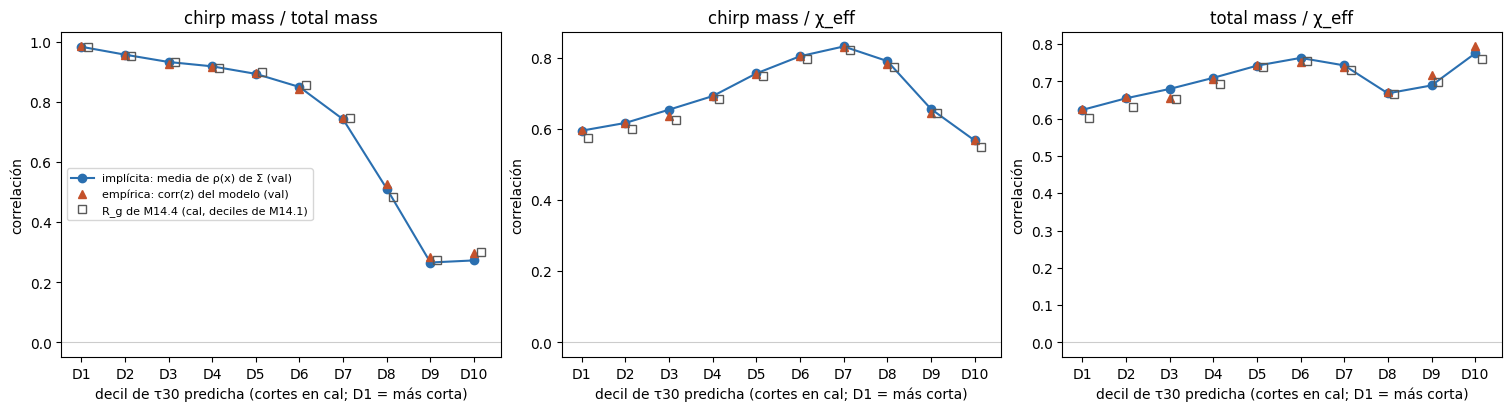

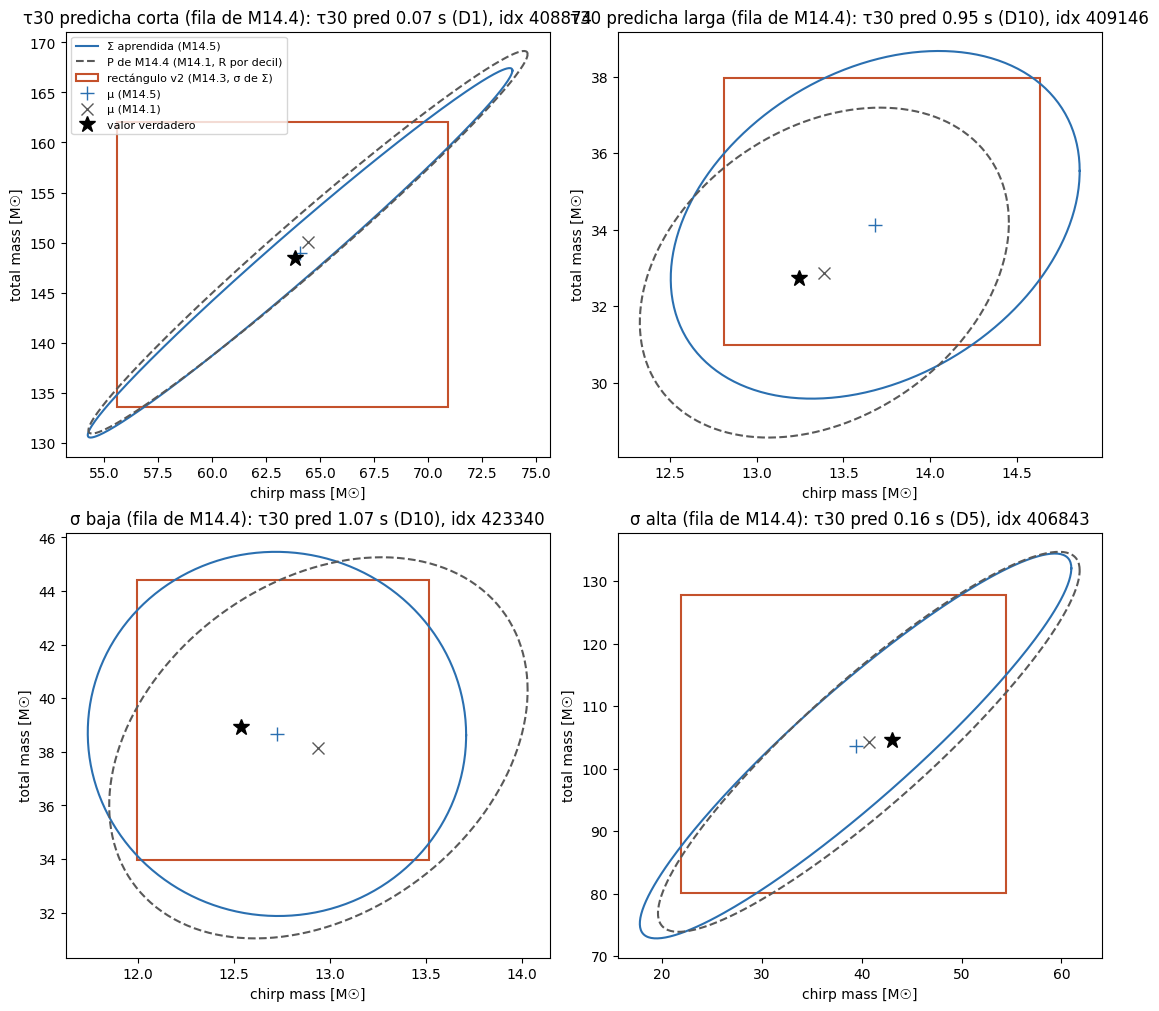

/data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/figures/M14_5a_4a_G3T_fullcov_s123_val_implied_vs_empirical_corr_by_tau_pred_decile_20261112T142455Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/figures/M14_5a_4a_G3T_fullcov_s123_val_implied_vs_empirical_corr_by_tau_pred_decile_20261112T142455Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/figures/M14_5a_4a_G3T_fullcov_s123_val_ellipses_2d_examples_20261112T142455Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/figures/M14_5a_4a_G3T_fullcov_s123_val_ellipses_2d_examples_20261112T142455Z.pdf


In [13]:
LNAME, UNITS, METH = CONFIG["labels"], CONFIG["units"], CONFIG["methods"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = []

def save_figure(fig, key):
    for ext in ("png", "pdf"):
        p = FIG_DIR / f"{CONFIG['fig_names'][key]}_{RUN_STAMP}.{ext}"
        with p.open("xb") as f:                      # never overwrites
            fig.savefig(f, format=ext, dpi=200, bbox_inches="tight")
        FIGURES.append(str(p))

# (a) Implied vs empirical correlation per predicted tau30 decile (val), with R_g of M14.4.
dec_tab = CORR[CORR.group != "global"]
x = np.arange(1, N_TAU_DECILES + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (i, j), pair in zip(axes, PAIRS, PAIR_NAMES):
    t = dec_tab[dec_tab.pair == pair]
    ax.plot(x, t.implied_mean, "o-", color=CONFIG["implied_color"], label="implícita: media de ρ(x) de Σ (val)")
    ax.plot(x, t.empirical_z, "^", color=CONFIG["empirical_color"], label="empírica: corr(z) del modelo (val)")
    ax.plot(x + 0.15, t.Rg_m14_4, "s", mfc="none", color=CONFIG["rg_color"], label="R_g de M14.4 (cal, deciles de M14.1)")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set(title=f"{LNAME[LABELS[i]]} / {LNAME[LABELS[j]]}", xticks=x, xticklabels=[f"D{v}" for v in x],
           xlabel="decil de τ30 predicha (cortes en cal; D1 = más corta)", ylabel="correlación")
axes[0].legend(fontsize=8)
save_figure(fig, "a")
plt.show()

# (b) The 4 representative val rows of M14.4 (same idx): 2D ellipses of learned Sigma and of P, and v2 rectangle.
REP_ROWS = {}
for name, r in M14_4_SUM["representative_rows"].items():
    i = int(np.searchsorted(IDX_VAL, r["idx"]))
    check(i < n_val and IDX_VAL[i] == r["idx"], f"representative row {name}: idx {r['idx']} in val")
    REP_ROWS[name] = i
MU_VAL_PHYS = V["pred"] * y_std + y_mean
MU_P_VAL_PHYS = P_SPLITS["val"]["pred"] * y_std + y_mean
Y_VAL_PHYS = V["y"] * y_std + y_mean
t_ell = np.linspace(0, 2 * np.pi, 300)
unit_circle = np.stack([np.cos(t_ell), np.sin(t_ell)])

def ellipse_S(i):
    sigma_phys = V["cov"][i][:2, :2] * np.outer(y_std[:2], y_std[:2])
    return MU_VAL_PHYS[i, :2, None] + np.sqrt(RADIUS_S["2D"]) * np.linalg.cholesky(sigma_phys) @ unit_circle

def ellipse_P(i):
    sd = P_SPLITS["val"]["sigma"][i, :2] * y_std[:2]
    sigma_phys = R_DEC_P[DEC_P["val"][i]][:2, :2] * np.outer(sd, sd)
    return MU_P_VAL_PHYS[i, :2, None] + np.sqrt(RADIUS_P["2D"]) * np.linalg.cholesky(sigma_phys) @ unit_circle

titles = dict(tau_short="τ30 predicha corta", tau_long="τ30 predicha larga", sigma_low="σ baja", sigma_high="σ alta")
fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, (name, i) in zip(axes.ravel(), REP_ROWS.items()):
    for m, ell in (("S", ellipse_S), ("P", ellipse_P)):
        ex, ey = ell(i)
        ax.plot(ex, ey, color=METH[m]["color"], ls=METH[m]["ls"], label=METH[m]["name"])
    lo, hi = V2_LOWER[i, :2], V2_UPPER[i, :2]
    ax.add_patch(plt.Rectangle(lo, *(hi - lo), fill=False, ec=CONFIG["v2"]["color"], lw=1.5, label=CONFIG["v2"]["name"]))
    ax.plot(*MU_VAL_PHYS[i, :2], "+", color=METH["S"]["color"], ms=10, label="μ (M14.5)")
    ax.plot(*MU_P_VAL_PHYS[i, :2], "x", color=METH["P"]["color"], ms=8, label="μ (M14.1)")
    ax.plot(*Y_VAL_PHYS[i, :2], "*", color=CONFIG["truth_color"], ms=12, label="valor verdadero")
    ax.set(title=f"{titles.get(name, name)} (fila de M14.4): τ30 pred {TAU_PRED['val'][i]:.2f} s (D{DEC['val'][i] + 1}), idx {IDX_VAL[i]}",
           xlabel=f"{LNAME['chirp_mass']} [{UNITS['chirp_mass']}]", ylabel=f"{LNAME['total_mass']} [{UNITS['total_mass']}]")
    ax.autoscale_view()
axes[0, 0].legend(fontsize=8)
save_figure(fig, "b")
plt.show()
print("\n".join(FIGURES))

## 9d. Enmienda 2: validez corregida y confirmación en test (post hoc)

**Enmienda 2** de `docs/experiments/M14_5_fullcov_head.md` (12-11-2026, tras ver val y antes de mirar test). Es una decisión post hoc; el veredicto pre-registrado de la sección 8 queda registrado tal cual.

- **Banda corregida:** el mismo procedimiento Monte Carlo que la celda 13 de `notebooks/m13/M13_13_mondrian_G3T.ipynb` (enmienda 6 de M13.13), reutilizado de esa celda sin copiarlo: c ~ Beta(k, n_cal − k + 1) y aciertos ~ Binomial(n_eval, c). Un solo bin (elipsoide global): k = ⌈(n_cal + 1)·0,9⌉, n_cal = 30 000, n_eval = 40 000 (val) y 30 000 (test). `default_rng(145003)`, 100 000 réplicas, un generador en orden fijo (val y luego test); banda al 95 %. Es la misma para S y P (mismo k y n_cal). Validez = cobertura **no por debajo** del límite inferior (la validez conformal solo exige no cubrir de menos).
- **Val:** cobertura 3D de S y de P frente a la banda corregida; solo descriptivo.
- **Test (30 000 filas):** predicciones `preds_test_G3T` de MODEL_TAG y de M14.1 (P), con los mismos gates que cal/val (procedencia, idx = split y row_ids del memmap, y = HDF5 de G3, Σ simétrica y definida positiva, σ = √diag Σ, P emparejado en las mismas filas). Se usan los radios de cal ya calculados (`RADIUS_S`, `RADIUS_P`; sin reajuste), deciles de τ30 y R_g de P de cal (M14.4). Cobertura 3D y Δ volumen 3D de S frente a P, con IC por bootstrap emparejado de filas de test (B = 2000, `default_rng(145004)`).
- **Veredicto:** se adopta S si en test (i) la cobertura 3D de S no está por debajo del límite inferior de la banda corregida y (ii) el IC superior de Δ < 0. En otro caso, P con la D del nuevo modelo.

In [14]:
# Corrected band (amendment 2): the three Monte Carlo statements of M13.13 cell 13 (amendment 6), taken by AST
# from that cell (not copied) and run with one bin: the global ellipsoid has one conformal rank k of n_cal.
M13_13_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_13_mondrian_G3T.ipynb"
NOTEBOOK_CELLS["M13_13"] = read_json(M13_13_NOTEBOOK)["cells"]
A2_MC_SEED, A2_MC_REPLICAS, A2_BAND_LEVEL = 145003, 100_000, 0.95
A2_N_EVAL = {"val": 40_000, "test": 30_000}

def extract_mc_band(source, cell_index):
    """Code of the statements that assign c, sim and (mc_lo, mc_hi) in the cell (each exactly once)."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    wanted = {"c": None, "sim": None, "mc_lo,mc_hi": None}
    for node in ast.walk(ast.parse(text)):
        if isinstance(node, ast.Assign) and len(node.targets) == 1:
            t = node.targets[0]
            key = (",".join(getattr(e, "id", "?") for e in t.elts) if isinstance(t, ast.Tuple)
                   else getattr(t, "id", None))
            if key in wanted:
                require(wanted[key] is None, f"{source} cell {cell_index}: {key} assigned more than once")
                wanted[key] = ast.get_source_segment(text, node)
    require(all(v is not None for v in wanted.values()), f"{source} cell {cell_index}: MC band statements not found")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=["MC band statements: " + "; ".join(wanted.values())],
                                                         sha256=hashlib.sha256(text.encode()).hexdigest())
    return compile("\n".join(wanted.values()), f"{source}_cell_{cell_index}_mc_band", "exec")

MC_BAND_CODE = extract_mc_band("M13_13", 13)
print(reused_sources["M13_13/cell_13"]["names"][0])

check(n_cal == 30_000 and n_val == A2_N_EVAL["val"], "amendment 2: n_cal = 30000, n_val = 40000")
check(K_RANK == int(np.ceil((n_cal + 1) * LEVEL)), "amendment 2: k = ceil((n_cal + 1) 0.9), same k for S and P")
rng_a2 = np.random.default_rng(A2_MC_SEED)          # one generator, fixed order: val, then test
A2_BAND = {}
for split, n_eval in A2_N_EVAL.items():
    ns = dict(np=np, rng=rng_a2, k_b=np.array([K_RANK]), n_b=np.array([n_cal]), m_b=np.array([n_eval]),
              n_test=n_eval, MC_REPLICAS=A2_MC_REPLICAS, MARGINAL_BAND_LEVEL=A2_BAND_LEVEL)
    exec(MC_BAND_CODE, ns)
    b_lo, b_hi = binom_band(n_eval)
    A2_BAND[split] = dict(n_cal=n_cal, k_rank=K_RANK, n_eval=n_eval, expected_coverage=K_RANK / (n_cal + 1),
                          mc_sim_mean=float(ns["sim"].mean()), mc95_lo=float(ns["mc_lo"]), mc95_hi=float(ns["mc_hi"]),
                          binomial95_lo_no_cal_noise=float(b_lo), binomial95_hi_no_cal_noise=float(b_hi))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(pd.DataFrame(A2_BAND).T)

MC band statements: c = rng.beta(k_b, n_b - k_b + 1, size=(MC_REPLICAS, len(k_b))); sim = rng.binomial(m_b, c).sum(axis=1) / n_test; mc_lo, mc_hi = np.quantile(sim, [(1 - MARGINAL_BAND_LEVEL) / 2, 1 - (1 - MARGINAL_BAND_LEVEL) / 2])


,n_cal,k_rank,n_eval,expected_coverage,mc_sim_mean,mc95_lo,mc95_hi,binomial95_lo_no_cal_noise,binomial95_hi_no_cal_noise
val,30000.0000,27001.0000,40000.0000,0.9000,0.9000,0.8955,0.9044,0.8971,0.9029
test,30000.0000,27001.0000,30000.0000,0.9000,0.9000,0.8952,0.9048,0.8966,0.9034


In [15]:
# Val: 3D coverage of S and P against the corrected band (descriptive only; the decision is in test).
band = A2_BAND["val"]
A2_VAL = pd.DataFrame([dict(method=m, dim="3D", n=n_val, coverage=float(covd["3D"].mean()), mc95_lo=band["mc95_lo"],
                            mc95_hi=band["mc95_hi"], not_below_lo=bool(covd["3D"].mean() >= band["mc95_lo"]),
                            within_band=bool(band["mc95_lo"] <= covd["3D"].mean() <= band["mc95_hi"]),
                            role="descriptive")
                       for m, covd in (("S", COVERED_S), ("P", COVERED_P))])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(A2_VAL)

,method,dim,n,coverage,mc95_lo,mc95_hi,not_below_lo,within_band,role
0,S,3D,40000,0.9030,0.8955,0.9044,True,True,descriptive
1,P,3D,40000,0.9007,0.8955,0.9044,True,True,descriptive


In [16]:
# Test predictions (first use of test in M14.5): same gates as cal/val (cell 6).
A2_TEST_PATHS = {"model": RESULTS / f"M13_3/{MODEL_TAG}/preds_test_G3T/test_predictions_embeddings.npz",
                 "P": RESULTS / f"M13_3/{P_TAG}/preds_test_G3T/test_predictions_embeddings.npz"}
for role, p in A2_TEST_PATHS.items():
    require(p.is_file(), f"Missing test predictions ({role}): {p}")
# Test inference reads fp16_memmap_heldout (configs/prediction/*_on_G3T_test.json), the cal memmap directory.
MEMMAP_DIRS["test"] = G3T_DIR / MEMMAP_NAMES["cal"]
N_TEST_EXPECTED = 30_000

TEST, A2_PROV = {}, {}
TEST["model"], A2_PROV["model/test"] = load_pred(A2_TEST_PATHS["model"], "test", EXPECTED_CHECKPOINT_NAME, "full")
TEST["P"], A2_PROV["P_m14_1/test"] = load_pred(A2_TEST_PATHS["P"], "test", f"{P_TAG}_final.pt", "diag")
d_t, dp_t = TEST["model"], TEST["P"]
n_test = len(split_indices["test"])
check(n_test == N_TEST_EXPECTED, f"test: n = {N_TEST_EXPECTED}")
check(d_t["idx"].shape == (n_test,) and len(np.unique(d_t["idx"])) == n_test, f"test: {n_test} unique idx")
for name, shape in (("pred", (n_test, 3)), ("sigma", (n_test, 3)), ("y", (n_test, 3)), ("emb", (n_test, EMB_DIM)),
                    ("cov", (n_test, 3, 3))):
    check(d_t[name].shape == shape and np.isfinite(d_t[name]).all(), f"test: {name} shape and finite")
check(np.array_equal(np.sort(d_t["idx"]), np.sort(split_indices["test"])), "test: idx = split membership")
row_ids = np.load(MEMMAP_DIRS["test"] / "row_ids_test.npy").astype(np.int64)
check(np.array_equal(np.sort(d_t["idx"]), np.sort(row_ids)), f"test: idx = row_ids of {MEMMAP_DIRS['test'].name}")
check(np.array_equal(dp_t["idx"], d_t["idx"]), "test: P (M14.1) idx = model idx (same order)")
check(np.allclose(dp_t["y"], d_t["y"], rtol=0, atol=Y_ATOL), "test: P (M14.1) y = model y")
check(np.isfinite(dp_t["pred"]).all() and dp_t["pred"].shape == (n_test, 3), "test: P (M14.1) pred shape and finite")
check(dp_t["sigma"].shape == (n_test, 3) and np.all(dp_t["sigma"] > 0), "test: P sigma > 0")
for s in ("cal", "val"):
    check(np.intersect1d(d_t["idx"], SPLITS[s]["idx"]).size == 0, f"no overlap test/{s}")

with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID_G3, "G3 HDF5 experiment_id (test)")
    check(str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 label order (test)")
    y_h5_test = read_hdf5_dataset_preserve_order(h, "y", d_t["idx"]).astype(float)
y_phys_t = d_t["y"] * y_std + y_mean
print("test: max |y_npz - y_G3h5| (physical) =", np.abs(y_phys_t - y_h5_test).max(0))
check(np.isclose(y_phys_t, y_h5_test, rtol=Y_RTOL, atol=Y_ATOL).all(), "test: y = y of the G3 HDF5")

C_t = d_t["cov"]
asym_t = float(np.abs(C_t - C_t.transpose(0, 2, 1)).max())
eig_min_t = np.linalg.eigvalsh(C_t).min(1)
dsig_t = float(np.abs(d_t["sigma"] - np.sqrt(np.diagonal(C_t, axis1=1, axis2=2))).max())
A2_COV_GATE = dict(split="test", max_asym=asym_t, min_eig=float(eig_min_t.min()), n_nonpd=int((eig_min_t <= 0).sum()),
                   max_abs_dsigma=dsig_t)
print(A2_COV_GATE)
check(asym_t <= SYM_ATOL, f"test: cov symmetric (max |S - S^T| <= {SYM_ATOL:g})")
check(np.all(eig_min_t > 0), "test: cov positive definite in every row")
check(dsig_t <= SIGMA_ATOL, f"test: sigma = sqrt(diag cov) (atol {SIGMA_ATOL:g})")
print("GATES superados:", len(CHECKS), "comprobaciones")

test: max |y_npz - y_G3h5| (physical) = [2.67509404e-06 7.89169644e-06 6.15315230e-08]
{'split': 'test', 'max_asym': 0.0, 'min_eig': 6.392038149577893e-05, 'n_nonpd': 0, 'max_abs_dsigma': 5.859592833168392e-08}
GATES superados: 201 comprobaciones


In [17]:
# Test: radii, tau decile edges and R_g are those of cal (cells 16 and 18); nothing is refitted.
# Same formulas as score_P / log_volume_P (cell 16) and log_volume_S (cell 18), written for an explicit split
# dict so that SPLITS and P_SPLITS keep only cal/val; checked against the val values of those cells.
def s_score_logv(d, dim):
    cols = list(DIMS[dim])
    sign, logdet = np.linalg.slogdet(d["cov"][:, cols][:, :, cols])
    check(np.all(sign > 0), f"S {dim}: det Sigma > 0")
    logdet_phys = logdet + 2 * np.log(y_std[cols]).sum()
    logv = np.log(UNIT_BALL[len(cols)]) + 0.5 * logdet_phys + 0.5 * len(cols) * np.log(RADIUS_S[dim])
    return mahalanobis(d, cols), logv

def p_score_logv(dp, dim):
    cols = list(DIMS[dim])
    z = ((dp["y"] - dp["pred"]) / dp["sigma"])[:, cols]
    tau = tau_newtonian(dp["pred"][:, 0] * y_std[0] + y_mean[0])
    dec = np.clip(np.searchsorted(TAU_EDGES_P[1:-1], tau, side="right"), 0, N_TAU_DECILES - 1)
    R = R_DEC_P[dec][:, cols][:, :, cols]
    score = np.einsum("ni,ni->n", z, np.linalg.solve(R, z[..., None])[..., 0])
    _, logdet_r = np.linalg.slogdet(R)
    log_scale = np.log(dp["sigma"][:, cols] * y_std[cols]).sum(1)
    logv = np.log(UNIT_BALL[len(cols)]) + log_scale + 0.5 * logdet_r + 0.5 * len(cols) * np.log(RADIUS_P[dim])
    return score, logv

sv, lv = s_score_logv(SPLITS["val"], "3D")
check(np.allclose(sv, S_SIG[("val", "3D")], rtol=0, atol=REPRO_ATOL) and np.allclose(lv, LOGV_S["3D"], rtol=0, atol=REPRO_ATOL),
      "amendment 2: S score/log volume functions reproduce val (cells 14, 18)")
pv, lpv = p_score_logv(P_SPLITS["val"], "3D")
check(np.allclose(pv, S_P[("val", "3D")], rtol=0, atol=REPRO_ATOL) and np.allclose(lpv, LOGV_P["3D"], rtol=0, atol=REPRO_ATOL),
      "amendment 2: P score/log volume functions reproduce val (cell 16)")

s_test, logv_S_test = s_score_logv(d_t, "3D")
p_test, logv_P_test = p_score_logv(dp_t, "3D")
check(np.isfinite(s_test).all() and np.isfinite(p_test).all() and np.isfinite(logv_S_test).all()
      and np.isfinite(logv_P_test).all(), "test: finite scores and log volumes")
COVERED_TEST = {"S": s_test <= RADIUS_S["3D"], "P": p_test <= RADIUS_P["3D"]}

band = A2_BAND["test"]
A2_TEST_COV = pd.DataFrame([dict(method=m, dim="3D", n=n_test, radius_cal=r, coverage=float(COVERED_TEST[m].mean()),
                                 mc95_lo=band["mc95_lo"], mc95_hi=band["mc95_hi"],
                                 not_below_lo=bool(COVERED_TEST[m].mean() >= band["mc95_lo"]),
                                 within_band=bool(band["mc95_lo"] <= COVERED_TEST[m].mean() <= band["mc95_hi"]),
                                 role="criterion" if m == "S" else "descriptive")
                            for m, r in (("S", RADIUS_S["3D"]), ("P", RADIUS_P["3D"]))])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(A2_TEST_COV)

A2_N_BOOT, A2_SEED = 2000, 145004
DLOG_T = logv_S_test - logv_P_test
A2_DELTA_POINT = float(100 * (np.exp(DLOG_T.mean()) - 1))
rng_a2b = np.random.default_rng(A2_SEED)
boot_a2 = np.empty(A2_N_BOOT)
for start in range(0, A2_N_BOOT, BOOT_BLOCK):
    b = min(BOOT_BLOCK, A2_N_BOOT - start)
    idx = rng_a2b.integers(0, n_test, size=(b, n_test))
    boot_a2[start:start + b] = 100 * (np.exp(DLOG_T[idx].mean(1)) - 1)
a = (1 - CI_LEVEL) / 2
a2_lo, a2_hi = (float(v) for v in np.quantile(boot_a2, [a, 1 - a]))
print(f"test: Δ volumen 3D S vs P = {A2_DELTA_POINT:+.3f} % [{a2_lo:+.3f}; {a2_hi:+.3f}] (bootstrap emparejado, B = {A2_N_BOOT})")

s_not_below = bool(A2_TEST_COV.set_index("method").loc["S", "not_below_lo"])
adopt_a2 = bool(s_not_below and a2_hi < 0)
A2_DECISION = dict(rule="adopt S if test 3D coverage of S >= corrected band lower limit and CI upper of Delta 3D < 0",
                   coverage_S_test=float(COVERED_TEST["S"].mean()), band_lo_test=band["mc95_lo"],
                   coverage_S_not_below_lo=s_not_below, delta_3d_pct=A2_DELTA_POINT, ci_lo_delta_3d_pct=a2_lo,
                   ci_hi_delta_3d_pct=a2_hi, adopt_learned_sigma=adopt_a2,
                   adopted=("Σ aprendida" if adopt_a2 else "P (D R_g D) con la D del nuevo modelo"),
                   preregistered_decision=DECISION["adopted"], post_hoc=True)
print("DECISIÓN (enmienda 2, post hoc):", A2_DECISION["adopted"],
      "| pre-registrada (sección 8):", DECISION["adopted"])

AMENDMENT_2 = dict(
    doc="docs/experiments/M14_5_fullcov_head.md, enmienda 2 (12-11-2026; post hoc, tras val y antes de test)",
    band=dict(procedure="M13_13 cell 13 (amendment 6) MC statements, one bin: c ~ Beta(k, n_cal - k + 1), "
                        "hits ~ Binomial(n_eval, c)", source=str(M13_13_NOTEBOOK),
              reused=reused_sources["M13_13/cell_13"], seed=A2_MC_SEED, replicas=A2_MC_REPLICAS, level=A2_BAND_LEVEL,
              order="one generator: val, then test", validity="coverage not below the lower limit", per_split=A2_BAND),
    val_descriptive=records(A2_VAL),
    test=dict(inputs={k: input_entry(p) for k, p in A2_TEST_PATHS.items()}, npz_provenance=A2_PROV,
              memmap_dir=str(MEMMAP_DIRS["test"]), cov_gate=A2_COV_GATE, n_test=n_test,
              radii_from_cal=dict(S_3D=RADIUS_S["3D"], P_3D=RADIUS_P["3D"]), coverage=records(A2_TEST_COV),
              delta=dict(point_pct=A2_DELTA_POINT, ci_lo_pct=a2_lo, ci_hi_pct=a2_hi, ci_level=CI_LEVEL,
                         n_boot=A2_N_BOOT, seed=A2_SEED,
                         note="Delta = 100 (exp(mean log V_S - mean log V_P) - 1), physical volume; paired row "
                              "bootstrap of test; radii fixed (cal)")),
    decision=A2_DECISION,
)

,method,dim,n,radius_cal,coverage,mc95_lo,mc95_hi,not_below_lo,within_band,role
0,S,3D,30000,6.0720,0.9017,0.8952,0.9048,True,True,criterion
1,P,3D,30000,6.4054,0.8991,0.8952,0.9048,True,True,descriptive


test: Δ volumen 3D S vs P = -27.595 % [-27.886; -27.304] (bootstrap emparejado, B = 2000)
DECISIÓN (enmienda 2, post hoc): Σ aprendida | pre-registrada (sección 8): P (D R_g D) con la D del nuevo modelo


## 11. Resumen JSON (modo `'x'`)

In [18]:
summary = dict(
    experiment="M14.5", preregistration="docs/experiments/M14_5_fullcov_head.md (11-11-2026)",
    run_stamp_utc=RUN_STAMP, model_tag=MODEL_TAG, c1_reference_tag=REF_TAG, p_tag=P_TAG,
    inputs=dict(pred={s: input_entry(p) for s, p in PRED_PATHS.items()}, trainer_val=input_entry(TRAIN_VAL_NPZ),
                c1_reference_val=input_entry(REF_VAL_NPZ), p_pred={s: input_entry(p) for s, p in P_PATHS.items()},
                run_info=str(RUN_INFO), history=str(HISTORY), split=str(SPLIT_PATH), label_stats=str(LABEL_STATS_PATH),
                g3_h5=str(G3_H5), m14_4_summary=str(M14_4_SUMMARY), m14_3_summary=str(M14_3_SUMMARY),
                m13_7_summary=str(M13_7_SUMMARY)),
    npz_provenance=NPZ_PROVENANCE, reused_sources=reused_sources,
    gates=dict(checks=CHECKS, cov=records(COV_GATE), val_reproduction=GATE_VAL, p_reproduction=P_REPRO,
               p_expected=P_EXPECTED),
    groups=dict(tau_pred_edges_cal_s=TAU_EDGES_CAL, tau_groups=TAU_GROUPS, sigma_chirp_cuts_cal_std=SIG_CHIRP_CUTS_CAL,
                snr_cuts_val=SNR_CUTS, snr_source=f"G3 nominal {SNR_KEY} of {G3_H5.name}, aligned by idx_val (truth)"),
    c1=dict(n_boot=N_BOOT_C1, seed=SEED_C1, ci_level=CI_LEVEL, margin_pct=C1_MARGIN_PCT,
            note="paired row bootstrap of val, one draw per replicate for the three labels", table=records(C1)),
    c2=dict(chi2_3_q90=CHI2_3_Q90, mean_band=C2_MEAN_BAND, frac_band=C2_FRAC_BAND, table=records(C2), verdict=C2_VERDICT,
            decides=False),
    c3=dict(level=LEVEL, k_rank=K_RANK, n_cal=n_cal, n_val=n_val, radius_S=RADIUS_S, radius_P=RADIUS_P,
            band_level=VALID_BAND_LEVEL, validity=records(VALIDITY), valid=VALID,
            n_boot=N_BOOT_C3, seed=SEED_C3, ci_level=CI_LEVEL,
            note="Delta = 100 (exp(mean log V_S - mean log V_P) - 1), physical volume; paired row bootstrap of val, "
                 "one draw per replicate for 3D and 2D; radii fixed (no cal noise)",
            gain=records(GAIN)),
    decision=DECISION,
    amendment_2=AMENDMENT_2,
    descriptive=dict(group_coverage=records(GROUP_COVERAGE), volumes=records(VOLUMES), correlations=records(CORR),
                     mondrian=dict(note="M13.7 cell 6 refitted on cal of this model (bundle in run_dir); v2 with M14.3 "
                                        "fit_v2/apply_v2, sigma = sqrt(diag Sigma)",
                                   run_dir=str(RUN_DIR), bundle=input_entry(BUNDLE_PATH), table=records(MONDRIAN),
                                   snr_gap=records(MONDRIAN_SNR_GAP))),
    figures=FIGURES, representative_rows={k: dict(row=i, idx=int(IDX_VAL[i])) for k, i in REP_ROWS.items()},
)
SUMMARY_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
SUMMARY_PATH = OUT_ROOT / f"M14_5_summary_{MODEL_TAG}_{SUMMARY_STAMP}.json"   # new file each time ('x' mode)
summary["summary_stamp_utc"] = SUMMARY_STAMP
OUT_ROOT.mkdir(parents=True, exist_ok=True)
with SUMMARY_PATH.open("x", encoding="utf-8") as f:
    json.dump(to_json(summary), f, indent=2, ensure_ascii=False)
print("Summary:", SUMMARY_PATH)
print("Decisión:", DECISION)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_5/M14_5a_4a_G3T_fullcov_s123/M14_5_summary_M14_5a_4a_G3T_fullcov_s123_20261112T142537Z.json
Decisión: {'c1_verdicts': {'chirp_mass': 'PASA', 'total_mass': 'PASA', 'chi_eff': 'PASA'}, 'c1_fails': False, 'valid_S_3D': False, 'delta_3d_pct': -28.11489067461732, 'ci_hi_delta_3d_pct': -27.86153583914462, 'adopt_learned_sigma': False, 'adopted': 'P (D R_g D) con la D del nuevo modelo'}


## Lectura (12-11-2026)

**Veredicto pre-registrado (sección 8): P**, porque S quedó 1e-4 por encima de una banda binomial bilateral sin ruido de cal. **Enmienda 2 (post hoc, criterio corregido antes de mirar test, confirmado en test): se adopta la Σ aprendida.**

### Verificado (M14.5a, 4a-G3T s123 con covarianza completa; una semilla)
- **Gates:** 110 (val) y 201 (con test) comprobaciones; Σ simétrica y definida positiva en todas las filas; la inferencia fp16 reproduce al entrenador (|ΔΣ| ≤ 3,6e-7).
- **C1 (frente a M14.1):** ΔRMSE +0,34 % / +0,27 % / +1,08 % [+0,65; +1,50] → PASA en las tres etiquetas.
- **C2 (no decide):** s = rᵀΣ⁻¹r frente a χ²₃: mean(s)/3 entre 0,968 y 1,003 y fracción ≤ q90 entre 0,906 y 0,912 en 7/7 celdas (grupos calculados desde X) → calibrada.
- **C3 (val), con la banda pre-registrada:** S 0,9030 (fuera por 1e-4, por exceso), P 0,9007; Δ volumen 3D S frente a P −28,1 % [−28,4; −27,9]; 2D −8,2 %.
- **Enmienda 2:**
  - banda Monte Carlo con ruido de cal: val [0,8955; 0,9044], test [0,8952; 0,9048];
  - val: S 0,9030 y P 0,9007, válidas;
  - **test: S 0,9017, válida; Δ volumen 3D −27,6 % [−27,9; −27,3] → Σ aprendida.**
- **Descriptivos:**
  - correlación implícita de Σ(x) por decil de τ30 predicha = empírica (𝓜–M_tot 0,985 → 0,27; M_tot–χ_eff 0,62 → 0,78; 𝓜–χ_eff máximo 0,83 en D7);
  - cobertura de S plana por terciles de SNR (0,899–0,908) y por grupos de τ (0,902–0,906);
  - volumen medio geométrico 3D: S 51,4; P 71,5; rectángulos v2 de M14.4 114,6;
  - Mondrian v2 con σ = √diag Σ reproduce M14.3: máx. |cob_t − 0,90| por SNR v1 0,086 / 0,050 / 0,026 frente a v2 0,003 / 0,004 / 0,011 (total / χ_eff / chirp).

### Interpretación
- La red aprende la estructura de degeneración evento a evento, y coincide con la medida empíricamente.
- La mayor parte de la ganancia sobre P (−28 % en 3D frente a −8 % en 2D) viene de las correlaciones con χ_eff, que varían de un evento a otro de formas que una R por tramos no captura (hipótesis, coherente con los números).
- **Error de diseño registrado:** se copió en este pre-registro la banda binomial bilateral sin ruido de cal después de haber visto su defecto en M14.4.

### No se puede concluir
- La variación entre semillas; el comportamiento en datos reales.
- El IC de volumen no incluye el ruido de cal.